# RIS / 02 — 5-year T-Note futures (`ZF`): stacked 1-minute days, discovery on H2 (2021–2025)

Protocol: [`RIS 001`](../../../discussions/Rate_Intraday_Seasonality/001_claude_ris01_preregistration.md), the bond seasonality design ([`BDS 001`](../../../discussions/Bond_Intraday_Seasonality/001_claude_bds01_preregistration.md)) applied to US rate futures (Databento best bid/offer once a minute, front contract).

Every trading day is laid on top of the others by minute of day, in two clocks (`NY`: 17:00→17:00 New York; `UTC`: 00:00→24:00), and every interval (start every 5 minutes, 15–240 minutes long: 2,704 tests) is tested for a non-zero mean. Its frozen candidates are confirmed on H1 (backward) in `03_cross_confirmation.ipynb`.

| Filter | Condition |
|---|---|
| D1 | Benjamini–Hochberg over this symbol's 2,704 tests, q ≤ 0.05 |
| D2 | same sign in ≥ 75% of counted years (4 of 5) |
| D3 | \|mean\| > quoted futures spread (median at start and end) + 0.70 bp |
| D0 | D1–D3 count above the 95th percentile of 20 rotated-day placebos |
| reported | Bonferroni over the 3 futures (\|t\| ≥ 4.52); trimmed mean |

Before scanning, the **contract rolls** (the continuous symbol moves to the next contract and the price jumps by the calendar spread) are found from the instrument id and the days containing them dropped, and so are days with an impossible 1-minute price spike (§2).

**Reads 2021–2025 only; 2026 is refused in code.** Writes `02/candidates_frozen.csv`: commit it before running `03_cross_confirmation.ipynb`.

`RIS_SYNTHETIC=1`: offline run on synthetic quotes (ZT: +3 bp/day injected 08:30–09:30 New York; all: a −30 bp roll every quarter).

In [1]:
SYMBOL = "ZF"
WINDOW = "H2"

import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("RIS_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("RIS_SYNTH_DIR") or tempfile.mkdtemp(prefix="ris_")
    os.environ["RIS_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F
from equity_trading import bond_seasonality as B

cfg = B.BDSConfig()
if SYNTHETIC:
    cfg = replace(cfg, n_placebo=3, n_boot=2_000)
INFO = B.info(SYMBOL)
SHORT = INFO["short"]
POOLED_T = F.bonferroni_t(len(F.intervals(cfg.fx())) * len(B.CLOCKS) * len(B.RATE_SYMBOLS))
HOURS = lambda clock, step: ([60 * h for h in range(0, 25, step)], [F.slot_label(clock, 60 * h).split()[1] for h in range(0, 25, step)])
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 120)
OUT = Path.cwd() / ("02_synthetic" if SYNTHETIC else "02"); OUT.mkdir(exist_ok=True)
START, END = B.windows_for(SYMBOL)[WINDOW]
print(f"{SYMBOL} ({INFO['name']}) | window {WINDOW} {START} -> {END} | bond_seasonality {B.BDS_VERSION} | "
      f"synthetic={SYNTHETIC} | pooled Bonferroni |t| {POOLED_T:.2f}")

ZF (5-year T-Note) | window H2 2021-01-01 -> 2025-12-31 | bond_seasonality 0.3.0 | synthetic=False | pooled Bonferroni |t| 4.52


## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"])
    for r, (px, drift, seed) in {"ZT": (105.0, 3.0, 21), "ZF": (115.0, 0.0, 22), "SR3C3": (96.0, 0.0, 23)}.items():
        if not (base / "Databento" / "bbo-1m" / r).exists():
            B.write_synthetic_rate(base, r, dt.date(2015, 12, 28), dt.date(2025, 12, 31), seed=seed, drift_bps=drift, price=px)

## 1. Download complete?

Weekday files from the symbol's first file in the window; at least 95% must exist. Sundays are expected only if the symbol is quoted on Sundays. Missing days are dropped from the stack (with the New York day after them, which spans the missing UTC day).

In [3]:
bd = B.load(SYMBOL, WINDOW, cfg)
fs = bd.files
print(f"{SYMBOL}: first file {fs['first_file']} | weekday files {fs['present_weekdays']}/{fs['expected_weekdays']} ({fs['share']:.2%}) | "
      f"quoted on Sundays: {fs['sunday_session']} | missing expected files {len(fs['missing'])}")
if fs["missing"]:
    print("missing (first 40):", [str(d) for d in fs["missing"][:40]])
assert fs["share"] >= cfg.min_file_share, "fewer than 95% of weekday files: download the missing days and rerun"

ZF: first file 2021-01-03 | weekday files 1299/1303 (99.69%) | quoted on Sundays: True | missing expected files 4
missing (first 40): ['2021-12-24', '2022-04-15', '2024-03-29', '2025-04-18']


## 2. Contract rolls and price spikes

The continuous front-contract symbol moves to the next contract at each roll (instrument id change); the price jumps by the calendar spread, so the days containing a roll are dropped. Chart: every break's |gap| (bps, log scale) with the rolls in red. Then the 1-minute spikes (≥ 100 bps, or ≥ 50 bps reversed by 80% within 5 quoted minutes) and the days dropped per clock, by reason.

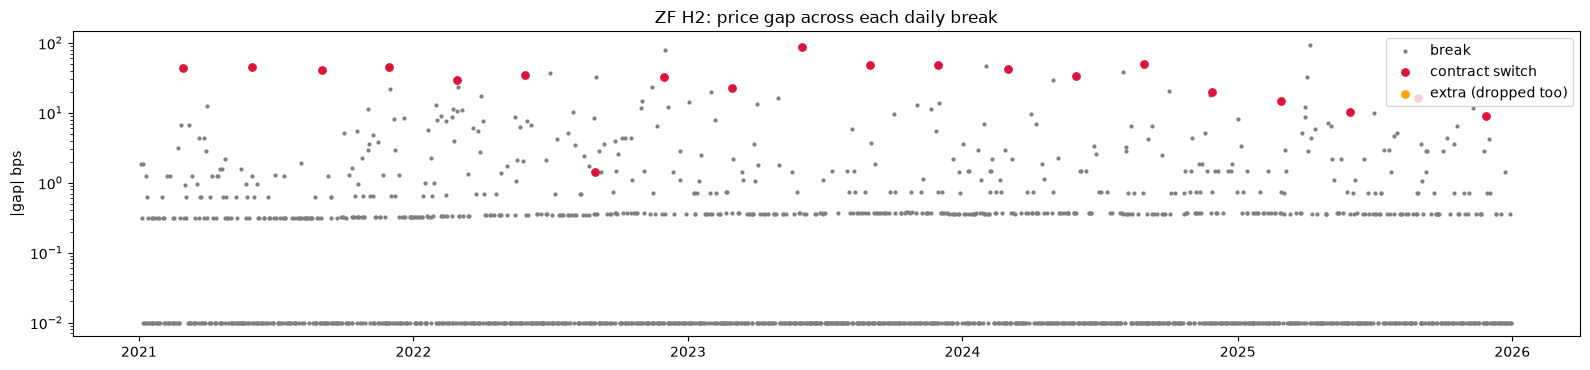

,quarter,before,after,break_minutes,gap_bps,ratio,extra,method,signature
0,2021-02,2021-02-26 22:00,2021-02-28 23:59,2999,44.07,NaN,False,instrument_change,
1,2021-05,2021-05-28 21:00,2021-05-30 19:00,2760,-45.64,NaN,False,instrument_change,
2,2021-08,2021-08-30 23:59,2021-08-31 23:59,1440,-41.29,NaN,False,instrument_change,
3,2021-11,2021-11-29 23:58,2021-11-29 23:59,1,-45.27,NaN,False,instrument_change,
4,2022-02,2022-02-27 23:58,2022-02-27 23:59,1,-29.10,NaN,False,instrument_change,
5,2022-05,2022-05-27 21:00,2022-05-29 19:00,2760,-35.08,NaN,False,instrument_change,
6,2022-08,2022-08-30 23:58,2022-08-30 23:59,1,1.41,NaN,False,instrument_change,
7,2022-11,2022-11-29 23:58,2022-11-29 23:59,1,32.21,NaN,False,instrument_change,
8,2023-02,2023-02-27 23:59,2023-02-28 23:59,1440,22.31,NaN,False,instrument_change,
9,2023-05,2023-05-30 23:59,2023-05-31 23:59,1440,87.41,NaN,False,instrument_change,


median |gap| over all 1707 breaks: 0.00 bps | switch methods: {'instrument_change': 20}
1-minute price spikes flagged: 0 on 0 days


,clock,days built,missing file,low coverage,contract switch,price spike,kept
0,NY,1303,4,41,12,0,1246
1,UTC,1302,4,41,19,0,1238


In [4]:
br = B.break_gaps(bd.minutes, cfg.break_minutes)
fig, ax = plt.subplots(figsize=(16, 3.8))
ax.scatter(br["after"], br["gap_bps"].abs().clip(lower=1e-2), s=4, color="grey", label="break")
if len(bd.rolls):
    m = bd.rolls[~bd.rolls["extra"]]; x = bd.rolls[bd.rolls["extra"]]
    ax.scatter(m["after"], m["gap_bps"].abs(), s=28, color="crimson", label="contract switch")
    ax.scatter(x["after"], x["gap_bps"].abs(), s=28, color="orange", label="extra (dropped too)")
ax.set_yscale("log"); ax.set_ylabel("|gap| bps"); ax.legend(); ax.set_title(f"{SYMBOL} {WINDOW}: price gap across each daily break")
plt.tight_layout(); plt.savefig(OUT / "02_breaks.png", dpi=110); plt.show()
r = bd.rolls.copy()
if len(r):
    r["before"] = r["before"].dt.strftime("%Y-%m-%d %H:%M"); r["after"] = r["after"].dt.strftime("%Y-%m-%d %H:%M")
display(r.round(2)); r.to_csv(OUT / "02_contract_switches.csv", index=False)
print(f"median |gap| over all {len(br)} breaks: {br['gap_bps'].abs().median():.2f} bps | switch methods: "
      f"{bd.rolls.loc[~bd.rolls['extra'], 'method'].value_counts().to_dict() if len(bd.rolls) else {}}")
sp = bd.spikes.copy()
print(f"1-minute price spikes flagged: {len(sp)} on {sp['ts'].dt.date.nunique() if len(sp) else 0} days")
if len(sp):
    display(sp.assign(ts=sp["ts"].dt.strftime("%Y-%m-%d %H:%M")).round(1).head(40))
sp.to_csv(OUT / "02_spikes.csv", index=False)
display(bd.drops)

## 3. Stack the days

In [5]:
panels = {(SYMBOL, c): bd.panels[c] for c in B.CLOCKS}
N_YEARS, NEED = B.d2_needed(bd.panels, cfg)
display(pd.DataFrame([{"clock": c, "days": len(p.dates), "first": str(p.dates[0]), "last": str(p.dates[-1]),
                       "counted years": ", ".join(map(str, B.counted_years(p, cfg))),
                       "median quoted minutes": int(np.median(p.coverage) * F.SLOTS),
                       "median spread bps": float(np.median(p.spread_bps()[:, np.median(p.spread_bps(), axis=0) < 50])),
                       "futures cost bps": B.cost_bps(p, cfg), "price first": float(p.mid[0, 0]), "price last": float(p.mid[-1, -1])}
                      for c, p in bd.panels.items()]).round(3))
print(f"D2: same sign in >= {NEED} of {N_YEARS} counted years")

,clock,days,first,last,counted years,median quoted minutes,median spread bps,futures cost bps,price first,price last
0,NY,1246,2021-01-04,2025-12-31,"2021, 2022, 2023, 2024, 2025",1383,0.717,1.416,126.152,109.230
1,UTC,1238,2021-01-04,2025-12-30,"2021, 2022, 2023, 2024, 2025",1382,0.717,1.416,126.129,109.418


D2: same sign in >= 4 of 5 counted years


## 4. The stacked day

Top: mean cumulative mid return from the day start (bps) ± 2 standard errors; grey: hours where the median spread is above twice its daily median (closed or thin). Bottom: the same path for each year. Real structure shows up in most years at the same time of day.

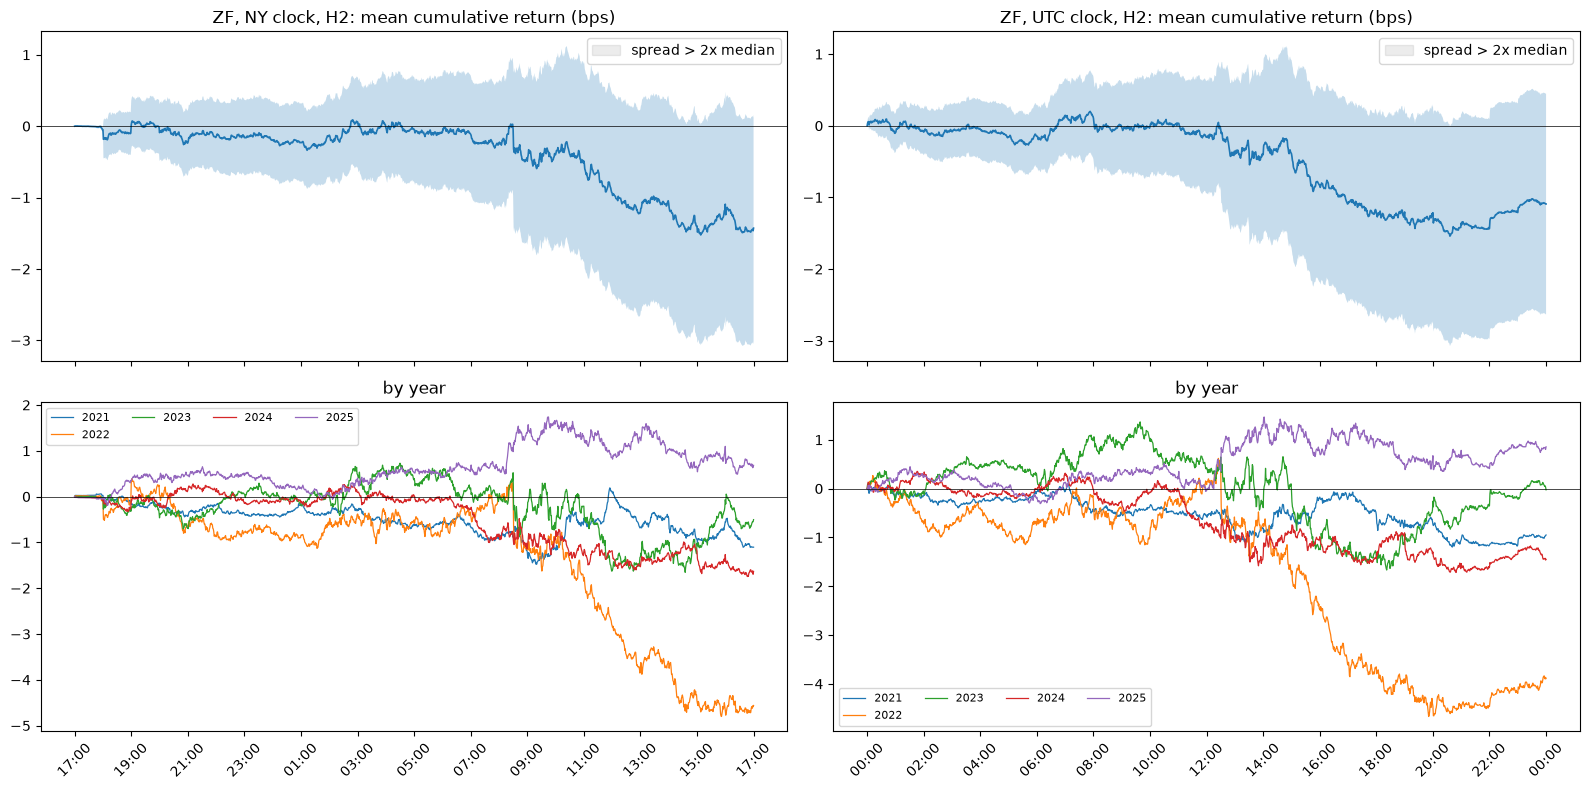

In [6]:
prof = {c: F.profile(bd.panels[c]) for c in B.CLOCKS}
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex="col")
for j, clock in enumerate(B.CLOCKS):
    pr, x = prof[clock], prof[clock].index / 60
    ax = axes[0, j]
    ax.plot(x, pr["cum_mean_bps"], lw=1.2)
    ax.fill_between(x, pr["cum_mean_bps"] - 2 * pr["cum_se_bps"], pr["cum_mean_bps"] + 2 * pr["cum_se_bps"], alpha=0.25)
    wide = (pr["spread_bps"] > 2 * pr["spread_bps"].median()).to_numpy()
    ax.fill_between(x, 0, 1, where=wide, transform=ax.get_xaxis_transform(), color="grey", alpha=0.15, label="spread > 2x median")
    ax.axhline(0, color="black", lw=0.5); ax.set_title(f"{SYMBOL}, {clock} clock, {WINDOW}: mean cumulative return (bps)"); ax.legend()
    yp = F.yearly_profiles(bd.panels[clock])
    for y in yp.columns:
        axes[1, j].plot(x, yp[y], lw=0.9, label=str(y))
    axes[1, j].axhline(0, color="black", lw=0.5); axes[1, j].legend(ncol=4, fontsize=8); axes[1, j].set_title("by year")
    t, l = HOURS(clock, 2)
    axes[1, j].set_xticks(np.array(t) / 60); axes[1, j].set_xticklabels(l, rotation=45)
plt.tight_layout(); plt.savefig(OUT / "04_stacked_day.png", dpi=110); plt.show()
pd.DataFrame({c: prof[c]["cum_mean_bps"] for c in B.CLOCKS}).to_csv(OUT / "04_profile_cum_mean.csv")

## 5. Activity and cost by minute of day

Mean absolute 1-minute return and median quoted spread (log scale), with one tick as a dashed line. Shows when the market is open and where trading is cheap; not a direction signal.

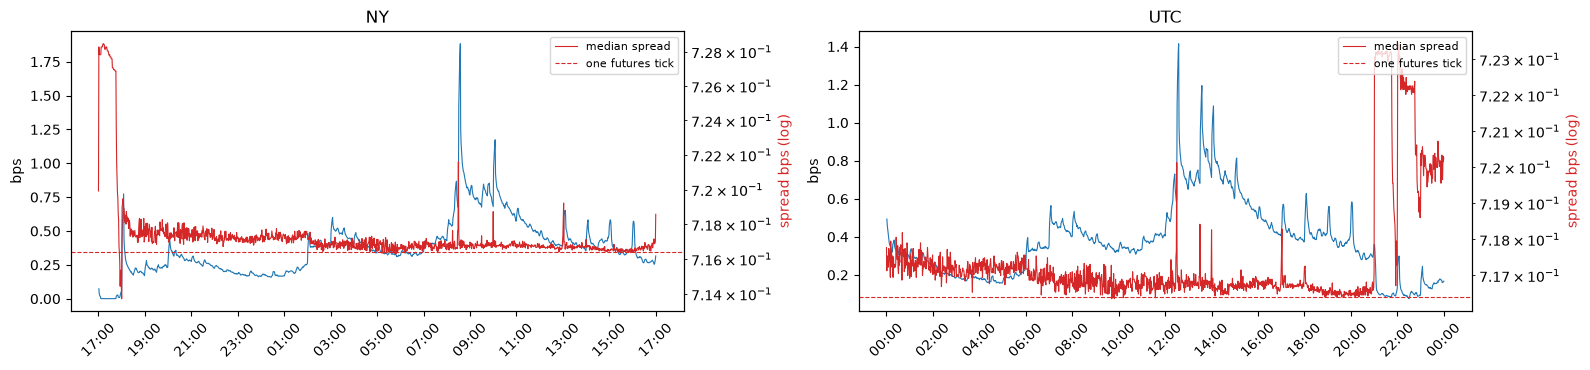

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for j, clock in enumerate(B.CLOCKS):
    pr, p = prof[clock], bd.panels[clock]
    ax = axes[j]; ax2 = ax.twinx()
    ax.plot(pr.index / 60, pr["abs_ret_bps"].rolling(5, min_periods=1).mean(), lw=0.8, label="mean |1-min return|")
    ax2.plot(pr.index / 60, pr["spread_bps"], lw=0.8, color="C3", label="median spread")
    ax2.axhline(float(B.tick_bps(SYMBOL, np.median(p.mid))), color="C3", ls="--", lw=0.8, label="one futures tick")
    ax2.set_yscale("log"); ax2.legend(loc="upper right", fontsize=8)
    t, l = HOURS(clock, 2); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=45)
    ax.set_ylabel("bps"); ax2.set_ylabel("spread bps (log)", color="C3"); ax.set_title(clock)
plt.tight_layout(); plt.savefig(OUT / "05_activity.png", dpi=110); plt.show()

## 6. 15-minute blocks: size and consistency

Each bar is one 15-minute block: its t-statistic, coloured by the share of years with the same sign. Dashed: the pooled Bonferroni line. Descriptive; the formal test is §7.

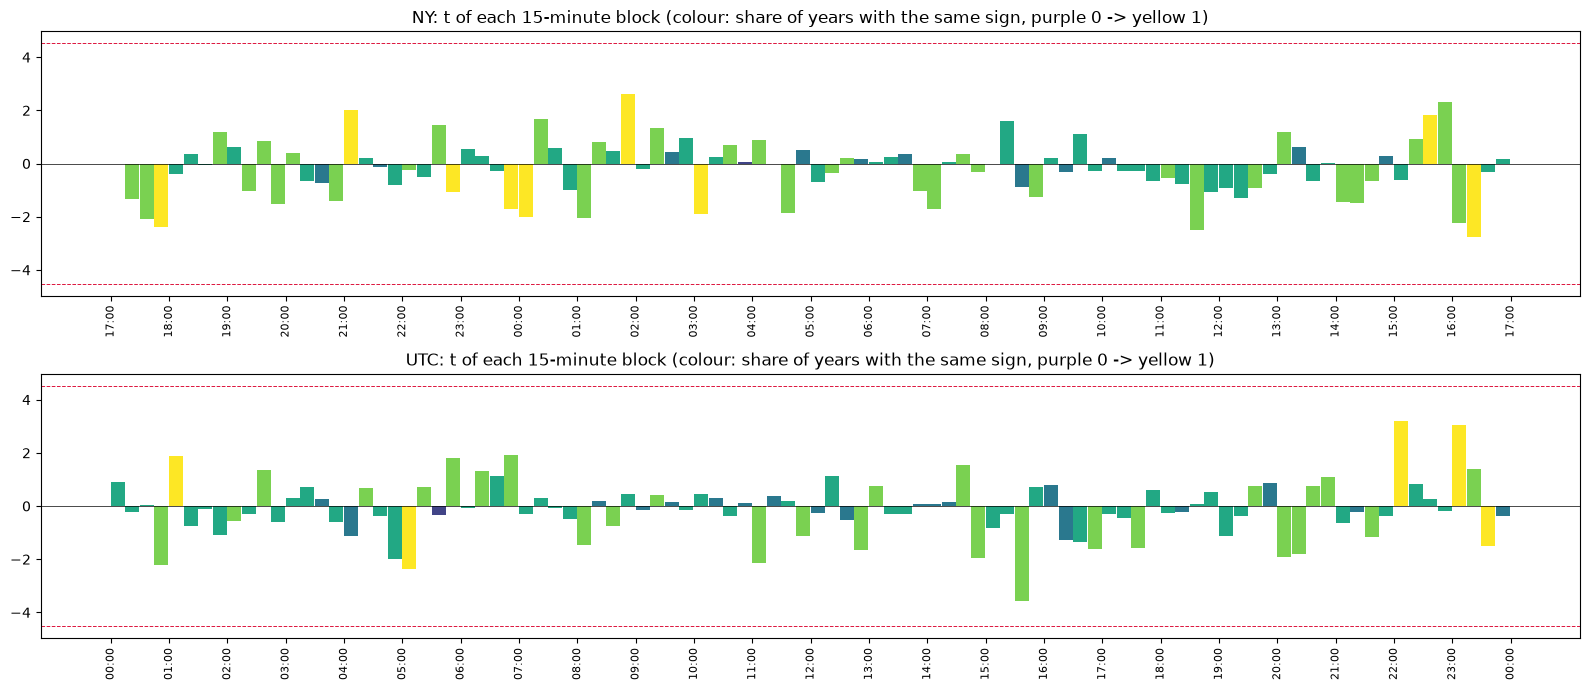

,clock,start,time,mean_bps,t,share_up,years_same_sign,n_years
62,UTC,930,UTC 15:30,-0.357,-3.559,0.415,4,5
88,UTC,1320,UTC 22:00,0.196,3.217,0.325,5,5
92,UTC,1380,UTC 23:00,0.140,3.048,0.310,5,5
93,NY,1395,NY 16:15,-0.164,-2.744,0.347,5,5
35,NY,525,NY 01:45,0.130,2.601,0.388,5,5
74,NY,1110,NY 11:30,-0.236,-2.492,0.418,4,5
3,NY,45,NY 17:45,-0.043,-2.399,0.222,5,5
20,UTC,300,UTC 05:00,-0.091,-2.365,0.288,5,5
91,NY,1365,NY 15:45,0.168,2.325,0.459,4,5
92,NY,1380,NY 16:00,-0.163,-2.240,0.376,4,5


In [8]:
bc = {c: F.block_consistency(bd.panels[c], 15) for c in B.CLOCKS}
fig, axes = plt.subplots(2, 1, figsize=(16, 7))
for ax, clock in zip(axes, B.CLOCKS):
    b = bc[clock]
    ax.bar(b["start"] / 60, b["t"], width=0.24, color=plt.cm.viridis(b["years_same_sign"] / b["n_years"]), align="edge")
    for s in (1, -1):
        ax.axhline(s * POOLED_T, color="crimson", ls="--", lw=0.7)
    ax.axhline(0, color="black", lw=0.5)
    t, l = HOURS(clock, 1); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=90, fontsize=8)
    ax.set_title(f"{clock}: t of each 15-minute block (colour: share of years with the same sign, purple 0 -> yellow 1)")
plt.tight_layout(); plt.savefig(OUT / "06_blocks.png", dpi=110); plt.show()
pd.concat(bc, names=["clock"]).to_csv(OUT / "06_blocks.csv")
display(pd.concat(bc, names=["clock"]).reset_index(level=0).dropna(subset=["t"]).sort_values("t", key=abs, ascending=False).head(15).round(3))

## 7. Interval scan: D1–D3 and the frozen candidates

Map: t-statistic of every interval by start time (x) and length (y); white = closed hours (no test). Black dots: intervals passing D1–D3.

ZF H2: tests 2,704 | D1 19 | D1+D2 19 | D1+D2+D3 0 | D1+D2+D3_cfd 0 | candidates 0 | pooled-Bonferroni |t| 1


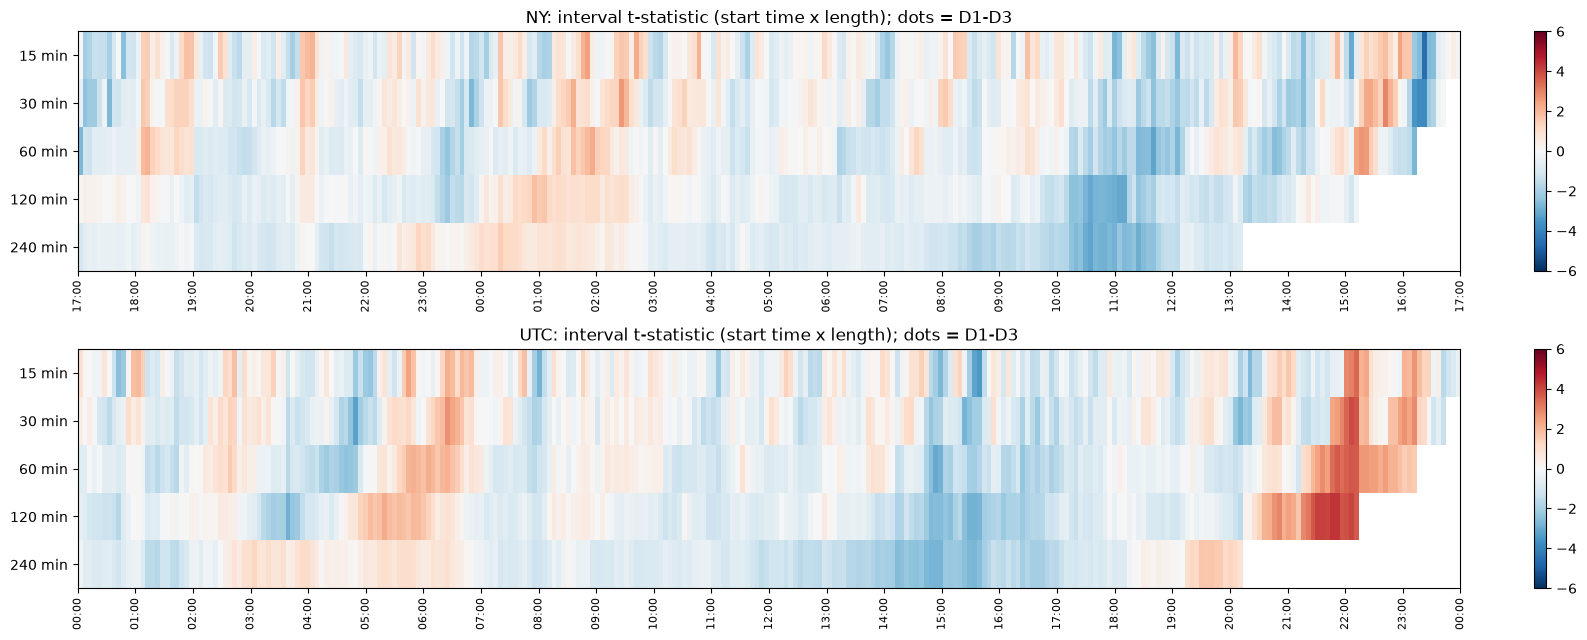

no candidates
frozen: candidates_frozen.csv sha256 7354c3c9758f95d38aefe5ce40a2504436080d2f2b40b357513993f20d0fd522


In [9]:
scan = pd.concat([B.scan_panel(bd.panels[c], cfg) for c in B.CLOCKS], ignore_index=True)
scan, cand = B.select(scan, cfg, NEED, SHORT, WINDOW)
scan["pooled_bonferroni"] = scan["t"].abs() >= POOLED_T
print(f"{SYMBOL} {WINDOW}: tests {int(scan['p'].notna().sum()):,} | D1 {int(scan['D1'].sum())} | D1+D2 {int((scan['D1'] & scan['D2']).sum())} | "
      f"D1+D2+D3 {int(scan['D123'].sum())} | D1+D2+D3_cfd {int((scan['D1'] & scan['D2'] & scan['D3_cfd']).sum())} | "
      f"candidates {len(cand)} | pooled-Bonferroni |t| {int(scan['pooled_bonferroni'].sum())}")
fig, axes = plt.subplots(2, 1, figsize=(16, 6.5))
for ax, clock in zip(axes, B.CLOCKS):
    s = scan[scan["clock"] == clock]
    grid = s.pivot(index="minutes", columns="start", values="t")
    im = ax.imshow(grid.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-6, vmax=6,
                   extent=[0, 24, len(grid) - 0.5, -0.5], interpolation="nearest")
    hit = s[s["D123"]]
    ax.scatter(hit["start"] / 60, [list(grid.index).index(m) for m in hit["minutes"]], s=6, color="black")
    ax.set_yticks(range(len(grid))); ax.set_yticklabels([f"{m} min" for m in grid.index])
    t, l = HOURS(clock, 1); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=90, fontsize=8)
    ax.set_title(f"{clock}: interval t-statistic (start time x length); dots = D1-D3")
    fig.colorbar(im, ax=ax, fraction=0.015)
plt.tight_layout(); plt.savefig(OUT / "07_scan_map.png", dpi=110); plt.show()
if len(cand):
    cand["pooled_bonferroni"] = cand["t"].abs() >= POOLED_T
    display(cand[B.CAND_COLS + ["pooled_bonferroni"]].round(3))
else:
    cand = pd.DataFrame(columns=B.CAND_COLS)
    print("no candidates")
scan[scan["D1"]].to_csv(OUT / "07_scan_D1_survivors.csv", index=False)
frozen = OUT / "candidates_frozen.csv"
cand[B.CAND_COLS].to_csv(frozen, index=False, float_format="%.6f")
sha = F.file_sha256(frozen)
print("frozen:", frozen.name, "sha256", sha)

## 8. Robustness of each candidate

Mean, 1%-trimmed mean, median and share of positive days in the trade direction (bps), then the mean by year. A mean carried by a few extreme days (a missed contract switch, a data release) shows a trimmed mean and median far below the mean.

In [10]:
if len(cand):
    rob = B.robustness(bd.panels, cand, cfg)
    display(rob.round(3)); rob.to_csv(OUT / "08_robustness.csv", index=False)
    ym = B.yearly_means(bd.panels, cand)
    display(ym.round(2)); ym.to_csv(OUT / "08_by_year.csv")
else:
    print("no candidates")

no candidates


## 9. Where the candidates sit

In [11]:
if len(cand):
    n = len(cand)
    fig, axes = plt.subplots(int(np.ceil(n / 2)), 2, figsize=(16, 3.2 * np.ceil(n / 2)), squeeze=False)
    for ax, (_, r) in zip(axes.flat, cand.iterrows()):
        pr = prof[r["clock"]]
        ax.plot(pr.index / 60, pr["cum_mean_bps"], lw=1)
        ax.axvspan(r["start"] / 60, r["end"] / 60, color="green" if r["direction"] > 0 else "red", alpha=0.2)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_title(f"{r['id']} {r['start_time']}-{r['end_time'].split()[1]} {'long' if r['direction'] > 0 else 'short'}: "
                     f"{r['mean_bps']:.2f} bp/day, t={r['t']:.1f}, cost {r['cost_bps']:.2f} bp", fontsize=9)
        t, l = HOURS(r["clock"], 2); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, fontsize=8)
    for ax in axes.flat[n:]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "09_candidates.png", dpi=110); plt.show()
else:
    print("no candidates")

no candidates


## 10. D0: rotated-day placebos

Each day's 1-minute returns rotated by a random offset (same returns and daily move, time of day destroyed); the full pipeline rerun 20 times. Takes several minutes.

In [12]:
pl = B.placebo_counts(bd.panels, cfg, NEED)
real = int(scan["D123"].sum())
p95 = float(np.percentile(pl["D1_D2_D3"], 95))
d0 = "STRUCTURE_FOUND" if real > p95 else "NO_STRUCTURE"
display(pl.describe().loc[["mean", "50%", "max"]])
print(f"{SYMBOL} {WINDOW}: real D1-D3 {real} vs placebo 95th percentile {p95:.1f} -> {d0}")
pl.to_csv(OUT / "10_placebo.csv", index=False)

,run,D1,D1_D2_D3,candidates
mean,9.5,0.05,0.0,0.0
50%,9.5,0.00,0.0,0.0
max,19.0,1.00,0.0,0.0


ZF H2: real D1-D3 0 vs placebo 95th percentile 0.0 -> NO_STRUCTURE


In [13]:
summary = {"study": "RIS01", "symbol": SYMBOL, "window": WINDOW, "dates": [str(START), str(END)],
           "bds_version": B.BDS_VERSION, "synthetic": SYNTHETIC,
           "files": {k: (str(v) if k == "first_file" else v) for k, v in bd.files.items() if k != "missing"},
           "missing_files": len(bd.files["missing"]), "contract_switches": int((~bd.rolls["extra"]).sum()) if len(bd.rolls) else 0,
           "drops": bd.drops.to_dict(orient="records"), "counted_years": N_YEARS, "d2_needed": NEED,
           "tests": int(scan["p"].notna().sum()), "D1": int(scan["D1"].sum()), "D1_D2": int((scan["D1"] & scan["D2"]).sum()),
           "D1_D2_D3": real, "D1_D2_D3_cfd": int((scan["D1"] & scan["D2"] & scan["D3_cfd"]).sum()), "candidates": int(len(cand)),
           "pooled_bonferroni_candidates": int(cand["pooled_bonferroni"].sum()) if len(cand) else 0,
           "placebo_D1_D2_D3": pl["D1_D2_D3"].tolist(), "D0": d0, "candidates_sha256": sha,
           "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(cfg).items()}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ("symbol", "window", "D1", "D1_D2", "D1_D2_D3", "D1_D2_D3_cfd", "candidates", "D0")}, indent=2))

{
  "symbol": "ZF",
  "window": "H2",
  "D1": 19,
  "D1_D2": 19,
  "D1_D2_D3": 0,
  "D1_D2_D3_cfd": 0,
  "candidates": 0,
  "D0": "NO_STRUCTURE"
}
